# 05 – Before vs. after 2016 (BIA 10-2474) – research question 3

**Comparison:** trials started **2005–2015** vs. **2017–2022**; 2016 (BIA 10-2474, January 2016)
is excluded as transition year (D09).

**Outcomes:** (a) terminated (any reason); (b) terminated for a safety-related reason.

**Approach:** logistic regression, period effect reported as **odds ratio (OR) post vs. pre with
95 % CI**, built up step by step to see how much of the crude difference is associated with the
trial mix. Results describe **associations, not causal effects** – many changes happened at the
same time (registration practice, trial mix, regulation).

| Analysis | Population | Purpose |
|---|---|---|
| A | analysis set: Completed or Terminated, start 2005–2022 | main comparison |
| B | **fixed observation window**: all started trials (any status, without Withdrawn), start ≤ 2020, outcome = terminated **within 3 years** after start | fair comparison without right-censoring |
| C | A and B without COVID-19-related terminations (D38) | sensitivity |

In [1]:
# --- Setup -------------------------------------------------------------------
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.proportion import proportion_confint

import viz_style as vs

vs.apply()
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)

PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = PROJECT_DIR / "data" / "processed"
FIGURES = PROJECT_DIR / "figures"

reasons = pd.read_parquet(PROCESSED / "why_stopped_final.parquet")[
    ["nct_id", "primary_reason_final", "safety_related_final"]]


def prepare(df):
    df = df.merge(reasons, on="nct_id", how="left")
    df["safety_termination"] = df["safety_related_final"].fillna(0).astype(int)
    df["covid_termination"] = (df["primary_reason_final"] == "COVID-19").astype(int)
    df["post"] = (df["start_year"] >= 2017).astype(int)
    df["oncology"] = (df["indication_group"] == "Oncology").astype(int)
    return df[df["start_year"] != 2016].copy()


analysis = prepare(pd.read_parquet(PROCESSED / "ctgov_analysis_dataset.parquet"))
window_all = prepare(pd.read_parquet(PROCESSED / "ctgov_window_dataset.parquet"))
print(f"Analysis set without 2016: {len(analysis):,} trials "
      f"(pre {int((analysis['post'] == 0).sum()):,}, post {int(analysis['post'].sum()):,})")

Analysis set without 2016: 7,447 trials (pre 4,644, post 2,803)


## 1. Fixed observation window (analysis B)

* Cohort: all trials started 2005–2020 (2016 excluded), **any status** (also still running or
  unknown), without *Withdrawn* (never started).
* Outcome: terminated **within 3 years (1,096 days) after the start date**. Termination date =
  actual completion date of the terminated trial (primary completion date if missing).
* Start years ≤ 2020: a 3-year window would technically be observable up to start 2023 (data cut-off
  October 2026), but the buffer allows for delayed status updates in the registry.
* Trials still running or with status *unknown* count as "not terminated within 3 years".

In [2]:
WINDOW_DAYS = 3 * 365.25
w = window_all[(window_all["start_year"] <= 2020) & (window_all["overall_status"] != "WITHDRAWN")].copy()
end_date = w["completion_date_dt"].fillna(w["primary_completion_date_dt"])
w["days_to_end"] = (end_date - w["start_date_dt"]).dt.days
term_no_date = (w["terminated"] == 1) & w["days_to_end"].isna()
print(f"Terminated trials without any end date (excluded): {term_no_date.sum()}")
w = w[~term_no_date].copy()
w["terminated_3y"] = ((w["terminated"] == 1) & (w["days_to_end"] <= WINDOW_DAYS)).astype(int)
w["safety_termination_3y"] = (w["terminated_3y"] & w["safety_termination"]).astype(int)
w["covid_termination_3y"] = (w["terminated_3y"] & w["covid_termination"]).astype(int)

print(f"Window cohort: {len(w):,} trials (pre {int((w['post'] == 0).sum()):,}, post 2017–2020 {int(w['post'].sum()):,})")
print(w.groupby("post")[["terminated", "terminated_3y", "safety_termination_3y"]].sum()
      .rename(index={0: "pre 2005–2015", 1: "post 2017–2020"}))
late = (w["terminated"] == 1) & (w["terminated_3y"] == 0)
print(f"Terminations after more than 3 years (not counted in the window outcome): {late.sum()}")

Terminated trials without any end date (excluded): 0
Window cohort: 7,303 trials (pre 4,925, post 2017–2020 2,378)
                terminated  terminated_3y  safety_termination_3y
post                                                            
pre 2005–2015          469            281                     36
post 2017–2020         431            228                     26
Terminations after more than 3 years (not counted in the window outcome): 391


## 2. Crude comparison

In [3]:
from statsmodels.stats.proportion import proportion_confint


def crude(df, outcome):
    rows = []
    for post, name in [(0, "pre"), (1, "post")]:
        g = df[df["post"] == post]
        k, n = int(g[outcome].sum()), len(g)
        lo, hi = proportion_confint(k, n, method="wilson")
        rows.append(f"{name}: {k}/{n} = {100 * k / n:.1f} % ({100 * lo:.1f}–{100 * hi:.1f})")
    return " | ".join(rows)


print("A (analysis set)")
print("  terminated        ", crude(analysis, "terminated"))
print("  safety-related    ", crude(analysis, "safety_termination"))
print("B (3-year window, start ≤ 2020)")
print("  terminated ≤ 3 y  ", crude(w, "terminated_3y"))
print("  safety-related    ", crude(w, "safety_termination_3y"))

A (analysis set)
  terminated         pre: 469/4644 = 10.1 % (9.3–11.0) | post: 620/2803 = 22.1 % (20.6–23.7)
  safety-related     pre: 54/4644 = 1.2 % (0.9–1.5) | post: 51/2803 = 1.8 % (1.4–2.4)
B (3-year window, start ≤ 2020)
  terminated ≤ 3 y   pre: 281/4925 = 5.7 % (5.1–6.4) | post: 228/2378 = 9.6 % (8.5–10.8)
  safety-related     pre: 36/4925 = 0.7 % (0.5–1.0) | post: 26/2378 = 1.1 % (0.7–1.6)


## 3. Models

Step-wise models for outcome (a):

| Model | Covariates (in addition to `post`) |
|---|---|
| M0 crude | – |
| M1 + trial mix | indication group, healthy volunteers, Phase 1/2 |
| M2 + design & sponsor | M1 + randomised, blinded, placebo, biological, sponsor type |
| M3 + ⚠️ site features | M2 + multinational, log(number of sites) |

Outcome (b) has only about 100 events → **parsimonious model** (`post` + oncology + healthy
volunteers + Phase 1/2), additionally fitted with **Firth's penalised likelihood** (bias reduction
for rare events; Wald CIs from the penalised fit).

In [4]:
REF_IND = "C(indication_group, Treatment('Other diseases'))"
REF_SP = "C(sponsor_group, Treatment('Academic / other'))"
MIX = f"{REF_IND} + healthy_volunteers + phase_1_2"
DESIGN = f"randomized + blinded + placebo + biological + {REF_SP}"
SITE = "multinational + log_n_locations"
MODELS_A = {"M0 crude": "post",
            "M1 + trial mix": f"post + {MIX}",
            "M2 + design & sponsor": f"post + {MIX} + {DESIGN}",
            "M3 + ⚠️ site features": f"post + {MIX} + {DESIGN} + {SITE}"}
MODEL_B = "post + oncology + healthy_volunteers + phase_1_2"


def fit(df, outcome, rhs):
    return smf.logit(f"{outcome} ~ {rhs}", data=df).fit(disp=False, maxiter=200)


def period_or(res):
    ci = res.conf_int().loc["post"]
    return np.exp(res.params["post"]), np.exp(ci[0]), np.exp(ci[1]), res.pvalues["post"]


def firth_logit(X, y, maxiter=200, tol=1e-9):
    """Firth-penalised logistic regression (Jeffreys prior); returns coefficients and Wald SEs."""
    X, y = np.asarray(X, float), np.asarray(y, float)
    beta = np.zeros(X.shape[1])
    for _ in range(maxiter):
        p = 1 / (1 + np.exp(-X @ beta))
        w_ = p * (1 - p)
        info = (X.T * w_) @ X
        info_inv = np.linalg.inv(info)
        h = np.einsum("ij,jk,ik->i", X, info_inv, X) * w_
        score = X.T @ (y - p + h * (0.5 - p))
        step = info_inv @ score
        beta += step
        if np.max(np.abs(step)) < tol:
            break
    return beta, np.sqrt(np.diag(info_inv))


def firth_period_or(df, outcome, rhs):
    import patsy
    y, X = patsy.dmatrices(f"{outcome} ~ {rhs}", df, return_type="dataframe")
    beta, se = firth_logit(X, y.iloc[:, 0])
    i = list(X.columns).index("post")
    return np.exp(beta[i]), np.exp(beta[i] - 1.96 * se[i]), np.exp(beta[i] + 1.96 * se[i])

In [5]:
rows = []


def run(label, df, outcome_a, outcome_b):
    for name, rhs in MODELS_A.items():
        res = fit(df, outcome_a, rhs)
        o, lo, hi, p = period_or(res)
        rows.append({"analysis": label, "outcome": "(a) terminated", "model": name, "OR post vs pre": o,
                     "CI low": lo, "CI high": hi, "p": p, "n": int(res.nobs), "events": int(df[outcome_a].sum())})
    res = fit(df, outcome_b, MODEL_B)
    o, lo, hi, p = period_or(res)
    rows.append({"analysis": label, "outcome": "(b) safety-related", "model": "parsimonious (logit)",
                 "OR post vs pre": o, "CI low": lo, "CI high": hi, "p": p, "n": int(res.nobs),
                 "events": int(df[outcome_b].sum())})
    o, lo, hi = firth_period_or(df, outcome_b, MODEL_B)
    rows.append({"analysis": label, "outcome": "(b) safety-related", "model": "parsimonious (Firth)",
                 "OR post vs pre": o, "CI low": lo, "CI high": hi, "p": np.nan, "n": len(df),
                 "events": int(df[outcome_b].sum())})


run("A  analysis set", analysis, "terminated", "safety_termination")
run("B  3-year window", w, "terminated_3y", "safety_termination_3y")
# C: sensitivity without COVID-19-related terminations (trials removed)
run("C  A without COVID-19 terminations", analysis[analysis["covid_termination"] == 0], "terminated", "safety_termination")
run("C  B without COVID-19 terminations", w[w["covid_termination_3y"] == 0], "terminated_3y", "safety_termination_3y")

results = pd.DataFrame(rows)
results["OR (95% CI)"] = results.apply(lambda r: f"{r['OR post vs pre']:.2f} ({r['CI low']:.2f}–{r['CI high']:.2f})", axis=1)
results.to_csv(PROCESSED / "table_pre_post_models.csv", index=False)
results[["analysis", "outcome", "model", "OR (95% CI)", "p", "n", "events"]]

,analysis,outcome,model,OR (95% CI),p,n,events
0,A analysis set,(a) terminated,M0 crude,2.53 (2.22–2.88),5.086852e-44,7447,1089
1,A analysis set,(a) terminated,M1 + trial mix,2.85 (2.49–3.27),2.388865e-50,7447,1089
2,A analysis set,(a) terminated,M2 + design & sponsor,2.75 (2.39–3.16),6.249622e-46,7447,1089
3,A analysis set,(a) terminated,M3 + ⚠️ site features,2.67 (2.32–3.07),4.085503e-42,7447,1089
4,A analysis set,(b) safety-related,parsimonious (logit),1.60 (1.08–2.35),1.771703e-02,7447,105
5,A analysis set,(b) safety-related,parsimonious (Firth),1.60 (1.09–2.34),NaN,7447,105
6,B 3-year window,(a) terminated,M0 crude,1.75 (1.46–2.10),1.525302e-09,7303,509
7,B 3-year window,(a) terminated,M1 + trial mix,1.73 (1.44–2.08),4.263867e-09,7303,509
8,B 3-year window,(a) terminated,M2 + design & sponsor,1.69 (1.40–2.03),3.222599e-08,7303,509
9,B 3-year window,(a) terminated,M3 + ⚠️ site features,1.84 (1.52–2.22),3.017414e-10,7303,509


## 4. Full coefficient table and collinearity check (M3, analysis A)

Odds ratios of all covariates (mutually adjusted) and variance inflation factors (VIF) – a first
look at collinearity (D30; detailed in Block 15). VIF > 5 would indicate unstable coefficients.

In [6]:
m3 = fit(analysis, "terminated", MODELS_A["M3 + ⚠️ site features"])
coef = pd.DataFrame({"OR": np.exp(m3.params), "CI low": np.exp(m3.conf_int()[0]),
                     "CI high": np.exp(m3.conf_int()[1]), "p": m3.pvalues}).drop("Intercept")
coef.index = coef.index.str.replace(r"C\(indication_group, Treatment\('Other diseases'\)\)\[T\.", "indication: ", regex=True) \
                       .str.replace(r"C\(sponsor_group, Treatment\('Academic / other'\)\)\[T\.", "sponsor: ", regex=True) \
                       .str.replace("]", "", regex=False)
coef.round(3).to_csv(PROCESSED / "table_pre_post_m3_coefficients.csv")
display_coef = coef.copy()
display_coef["OR (95% CI)"] = display_coef.apply(lambda r: f"{r['OR']:.2f} ({r['CI low']:.2f}–{r['CI high']:.2f})", axis=1)
display_coef[["OR (95% CI)", "p"]]

,OR (95% CI),p
indication: Cardiovascular,0.94 (0.56–1.57),8.129556e-01
indication: Healthy volunteers – no target condition,0.76 (0.51–1.12),1.678718e-01
indication: Immunology & inflammation,1.28 (0.85–1.92),2.344171e-01
indication: Infectious diseases & vaccines,0.86 (0.56–1.31),4.743497e-01
indication: Metabolic & endocrine,0.65 (0.40–1.04),7.414383e-02
indication: Nervous system & mental disorders,1.23 (0.85–1.79),2.687783e-01
indication: Oncology,2.14 (1.56–2.94),2.847435e-06
indication: Respiratory,0.72 (0.43–1.22),2.211031e-01
sponsor: Government / network / other,0.41 (0.16–1.07),6.737484e-02
sponsor: Industry,1.08 (0.87–1.34),5.075229e-01


In [7]:
X = m3.model.exog
names = m3.model.exog_names
vif = pd.Series([variance_inflation_factor(X, i) for i in range(1, X.shape[1])], index=names[1:], name="VIF")
vif.index = vif.index.str.replace(r"C\(.*?\)\[T\.", "", regex=True).str.replace("]", "", regex=False)
print(f"Max VIF: {vif.max():.2f} ({vif.idxmax()})")
vif.sort_values(ascending=False).round(2).head(8)

Max VIF: 4.60 (Oncology)


Oncology                                    4.60
Healthy volunteers – no target condition    3.89
blinded                                     3.60
log_n_locations                             3.48
multinational                               3.25
placebo                                     2.97
healthy_volunteers                          2.66
Infectious diseases & vaccines              2.26
Name: VIF, dtype: float64

## 5. Forest plot of the period effect

Saved figure: 07_pre_post_2016_odds_ratios.png


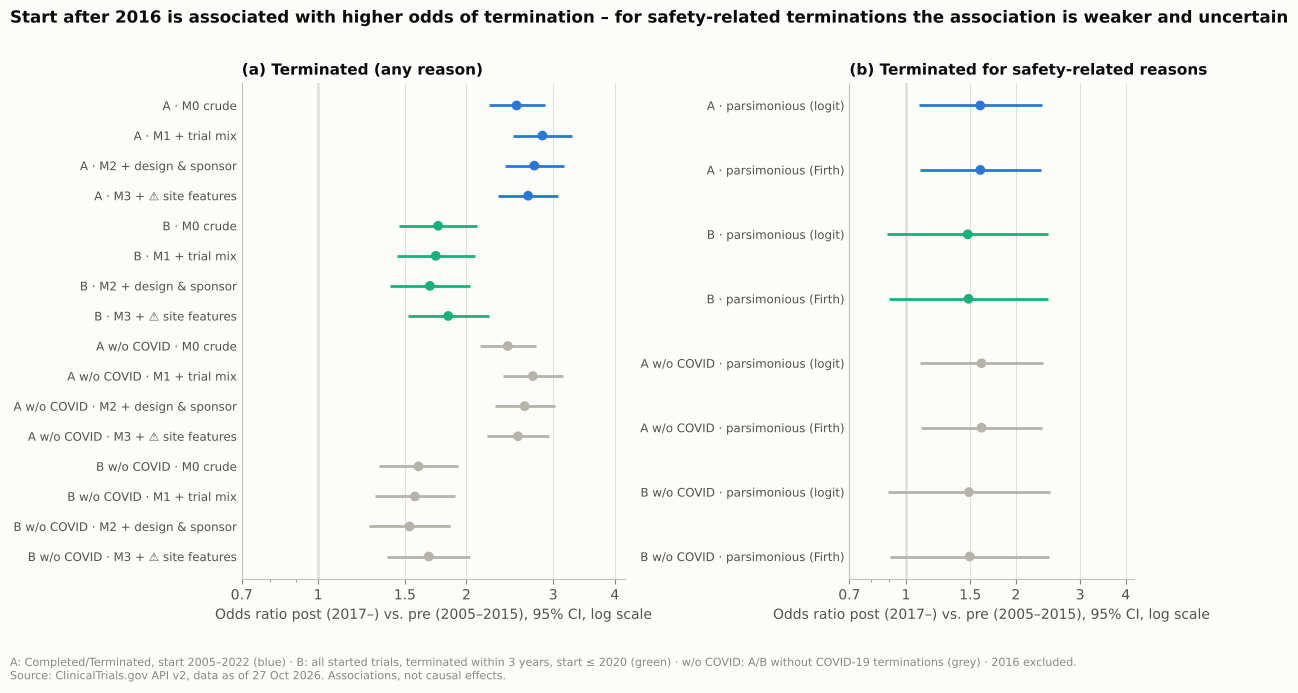

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 6.4), gridspec_kw={"width_ratios": [1.35, 1]})
order_a = [(a, m) for a in ["A  analysis set", "B  3-year window", "C  A without COVID-19 terminations",
                            "C  B without COVID-19 terminations"] for m in MODELS_A]
order_b = [(a, m) for a in ["A  analysis set", "B  3-year window", "C  A without COVID-19 terminations",
                            "C  B without COVID-19 terminations"] for m in ["parsimonious (logit)", "parsimonious (Firth)"]]
for ax, outcome, order, title in [(axes[0], "(a) terminated", order_a, "(a) Terminated (any reason)"),
                                  (axes[1], "(b) safety-related", order_b, "(b) Terminated for safety-related reasons")]:
    sub = results[results["outcome"] == outcome].set_index(["analysis", "model"]).loc[order].reset_index()
    y = np.arange(len(sub))[::-1]
    colors = [vs.SERIES[0] if a.startswith("A") else vs.SERIES[2] if a.startswith("B") else vs.NEUTRAL
              for a in sub["analysis"]]
    ax.axvline(1, color=vs.INK_MUTED, lw=1, zorder=1)
    ax.hlines(y, sub["CI low"], sub["CI high"], colors=colors, lw=2, zorder=2)
    ax.scatter(sub["OR post vs pre"], y, c=colors, s=36, zorder=3)
    short = {"A  analysis set": "A", "B  3-year window": "B", "C  A without COVID-19 terminations": "A w/o COVID",
             "C  B without COVID-19 terminations": "B w/o COVID"}
    labels = [f"{short[a]} · {m}" for a, m in zip(sub["analysis"], sub["model"])]
    ax.set_yticks(y, labels, fontsize=8.5)
    ax.tick_params(axis="y", length=0)
    ax.set_xscale("log")
    ax.set_xlim(0.7, 4.2)
    ax.set_xticks([0.7, 1, 1.5, 2, 3, 4], ["0.7", "1", "1.5", "2", "3", "4"])
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    ax.set_xlabel("Odds ratio post (2017–) vs. pre (2005–2015), 95% CI, log scale")
    ax.set_title(title, fontsize=11)
fig.suptitle("Start after 2016 is associated with higher odds of termination – for safety-related "
             "terminations the association is weaker and uncertain", x=0.01, ha="left", fontsize=12, fontweight="bold")
vs.source_note(fig, "A: Completed/Terminated, start 2005–2022 (blue) · B: all started trials, terminated within 3 years, "
               "start ≤ 2020 (green) · w/o COVID: A/B without COVID-19 terminations (grey) · 2016 excluded.\n"
               "Source: ClinicalTrials.gov API v2, data as of 27 Oct 2026. Associations, not causal effects.", y=-0.03)
fig.tight_layout(rect=(0, 0, 1, 0.97))
vs.save(fig, FIGURES / "07_pre_post_2016_odds_ratios.png")
plt.show()

## 6. Summary (associations, not causal effects)

**(a) Termination for any reason**

* Crude (analysis A): 10.1 % (pre) vs. 22.1 % (post) – OR **2.53** (95 % CI 2.22–2.88).
* Adjusting for the **trial mix** (indication, healthy volunteers, Phase 1/2), design, sponsor and
  the ⚠️ site features does **not reduce** the association (OR 2.67–2.85). The rise is therefore
  **not explained by the measured trial mix**.
* **Fair comparison with a fixed 3-year window** (analysis B, start ≤ 2020): terminated within 3
  years 5.7 % vs. 9.6 % – OR **1.75** (1.46–2.10), adjusted 1.69–1.84. About half of the crude
  association (on the log-odds scale) is explained by **right-censoring**, but a clear association
  remains.
* Without COVID-19-related terminations the results hardly change (A: 2.43–2.73; B: 1.53–1.68).

**(b) Safety-related termination** (105 events in A, 62 in B – parsimonious model)

* Analysis A: 1.2 % vs. 1.8 % – OR **1.60** (1.08–2.35); Firth regression gives the same result.
* Fair window B: 0.7 % vs. 1.1 % – OR **1.48** (0.89–2.46), CI includes 1.
* → a **weak and not robust** association; the data do **not** show a reduction of safety-related
  terminations after 2016, and no clear increase in the fair comparison either.

**Other covariates (M3, analysis A, mutually adjusted):** oncology OR 2.14, Phase 1/2 1.70,
multinational 1.70, placebo-controlled 2.01, healthy volunteers 0.59, randomised 0.68. Max VIF 4.6
(oncology) – no severe collinearity (detailed check in Block 15, D30).

**Interpretation:** trials started after 2016 are associated with higher odds of termination,
independent of the measured trial mix and partly beyond right-censoring. This cannot be attributed
to BIA 10-2474 or the revised first-in-human guideline: registration and status-update practice,
portfolio decisions and trial complexity changed over the same period.

# Part 2 – Sensitivity analyses (Block 14)

Each analysis changes one assumption and re-estimates the period effect (OR post vs. pre):
crude (M0) and fully adjusted (M3) for outcome (a), parsimonious model for outcome (b) where at
least about 40 events are available.

| | Sensitivity analysis | Population / change |
|---|---|---|
| S1 | without retrospectively registered trials (D28) | registered after primary completion excluded |
| S2 | start ≤ 2019 / ≤ 2020 (D26) | analysis A restricted |
| S3 | subgroups | healthy volunteers vs. patients, with/without oncology |
| S4 | interaction period × healthy volunteers | does the period effect differ? |
| S5 | 2-year window | terminated within 2 years, start ≤ 2020 |
| S6 | worst case | status *Unknown* counted as terminated |
| S7 | EudraCT strict definition (D22) | "Prematurely Ended" in all reporting countries |

In [9]:
sens = []
MIN_EVENTS_B = 40


def add_sens(label, df, out_a, out_b=None):
    row = {"scenario": label, "n": len(df), "events (a)": int(df[out_a].sum())}
    for name in ["M0 crude", "M3 + ⚠️ site features"]:
        o, lo, hi, p_ = period_or(fit(df, out_a, MODELS_A[name]))
        row[f"(a) {name.split()[0]}"] = f"{o:.2f} ({lo:.2f}–{hi:.2f})"
        row[f"_a_{name.split()[0]}"] = (o, lo, hi)
    if out_b is not None:
        ev = int(df[out_b].sum())
        row["events (b)"] = ev
        if ev >= MIN_EVENTS_B:
            o, lo, hi, p_ = period_or(fit(df, out_b, MODEL_B))
            row["(b) parsimonious"] = f"{o:.2f} ({lo:.2f}–{hi:.2f})"
            row["_b"] = (o, lo, hi)
        else:
            row["(b) parsimonious"] = f"not estimated (< {MIN_EVENTS_B} events)"
    sens.append(row)


# Reference: main analyses
add_sens("A  main analysis", analysis, "terminated", "safety_termination")
add_sens("B  3-year window (main)", w, "terminated_3y", "safety_termination_3y")

# S1 – without retrospectively registered trials
add_sens("S1 A without retrospective registration", analysis[analysis["registered_after_completion"] == 0],
         "terminated", "safety_termination")
add_sens("S1 B without retrospective registration", w[w["registered_after_completion"] == 0],
         "terminated_3y", "safety_termination_3y")
print("Retrospectively registered (excluded in S1): A",
      int(analysis["registered_after_completion"].sum()), "| B", int(w["registered_after_completion"].sum()))

# S2 – start year ≤ 2019 / ≤ 2020
add_sens("S2 A start ≤ 2019", analysis[analysis["start_year"] <= 2019], "terminated", "safety_termination")
add_sens("S2 A start ≤ 2020", analysis[analysis["start_year"] <= 2020], "terminated", "safety_termination")

# S5 – 2-year window
w["terminated_2y"] = ((w["terminated"] == 1) & (w["days_to_end"] <= 2 * 365.25)).astype(int)
w["safety_termination_2y"] = (w["terminated_2y"] & w["safety_termination"]).astype(int)
add_sens("S5 2-year window", w, "terminated_2y", "safety_termination_2y")

# S6 – worst case: status Unknown counted as terminated
a_wc = analysis.copy()
unknown = window_all[window_all["overall_status"] == "UNKNOWN"].copy()
unknown["terminated"] = 1
a_wc = pd.concat([a_wc, unknown], ignore_index=True)
add_sens("S6 A worst case (Unknown = terminated)", a_wc, "terminated")
w_wc = w.copy()
w_wc.loc[w_wc["overall_status"] == "UNKNOWN", "terminated_3y"] = 1
add_sens("S6 B worst case (Unknown = terminated)", w_wc, "terminated_3y")
print("Unknown status:", int((unknown["post"] == 0).sum()), "pre /", int(unknown["post"].sum()), "post (analysis A);",
      int((w["overall_status"] == "UNKNOWN").sum()), "in window B")

Retrospectively registered (excluded in S1): A 725 | B 705


Unknown status: 246 pre / 189 post (analysis A); 369 in window B


### S3 – Subgroups: healthy volunteers vs. patients, with and without oncology

Within each subgroup the indication term is kept where it varies (patients) and dropped for
healthy-volunteer trials where it would be nearly constant.

In [10]:
# Sponsor as industry yes/no in subgroups: the government/network group has 0 terminations among
# healthy-volunteer trials (0/24) -> quasi-separation with the 3-level variable
DESIGN_SUB = "randomized + blinded + placebo + biological + industry_sponsor"
MODEL_SUB = f"post + phase_1_2 + {DESIGN_SUB} + {SITE}"
sub_rows = []
for pop, hv in [("Healthy volunteers", 1), ("Patients", 0)]:
    for onc_label, keep in [("all indications", lambda d: d.index == d.index), ("excluding oncology", lambda d: d["oncology"] == 0)]:
        for an, df, out in [("A", analysis, "terminated"), ("B 3-year window", w, "terminated_3y")]:
            d = df[(df["healthy_volunteers"] == hv)]
            d = d[keep(d)]
            if hv == 0:   # 9 patient trials in the healthy-volunteer indication group -> merged (sparse cell)
                d = d.assign(indication_group=d["indication_group"].replace(
                    {"Healthy volunteers – no target condition": "Other diseases"}))
            rhs = MODEL_SUB if hv == 1 else f"{REF_IND} + {MODEL_SUB}"
            o0, l0, h0, _ = period_or(fit(d, out, "post"))
            o3, l3, h3, _ = period_or(fit(d, out, rhs))
            pre_r = 100 * d.loc[d["post"] == 0, out].mean()
            post_r = 100 * d.loc[d["post"] == 1, out].mean()
            sub_rows.append({"population": pop, "indications": onc_label, "analysis": an, "n": len(d),
                             "pre %": round(pre_r, 1), "post %": round(post_r, 1),
                             "OR crude": f"{o0:.2f} ({l0:.2f}–{h0:.2f})", "OR adjusted": f"{o3:.2f} ({l3:.2f}–{h3:.2f})",
                             "_adj": (o3, l3, h3)})
subgroups = pd.DataFrame(sub_rows)
subgroups.drop(columns="_adj").to_csv(PROCESSED / "table_sensitivity_subgroups.csv", index=False)
subgroups.drop(columns="_adj")

,population,indications,analysis,n,pre %,post %,OR crude,OR adjusted
0,Healthy volunteers,all indications,A,3491,4.7,9.0,2.00 (1.52–2.63),1.86 (1.41–2.47)
1,Healthy volunteers,all indications,B 3-year window,3150,4.1,8.9,2.29 (1.69–3.11),2.14 (1.57–2.92)
2,Healthy volunteers,excluding oncology,A,3411,4.6,8.9,2.01 (1.52–2.66),1.85 (1.39–2.46)
3,Healthy volunteers,excluding oncology,B 3-year window,3087,4.2,8.7,2.20 (1.62–2.99),2.05 (1.49–2.80)
4,Patients,all indications,A,3956,14.5,35.3,3.21 (2.75–3.75),3.04 (2.58–3.58)
5,Patients,all indications,B 3-year window,4153,6.9,10.1,1.51 (1.20–1.90),1.74 (1.36–2.21)
6,Patients,excluding oncology,A,1560,9.8,22.0,2.60 (1.94–3.49),2.48 (1.82–3.36)
7,Patients,excluding oncology,B 3-year window,1603,5.6,9.9,1.87 (1.25–2.80),1.71 (1.13–2.59)


### S4 – Interaction period × healthy volunteers

Model M3 with an added term `post × healthy_volunteers`. The **interaction OR** is the ratio of
the period ORs (healthy volunteers / patients); 1 = same period effect in both groups. The
revised first-in-human guideline (2017) mainly concerns first-in-human trials, many of them in
healthy volunteers – a different period effect in this group would be a hint (not a proof) of a
specific change.

In [11]:
def interaction(df, outcome, rhs_base, label):
    res = fit(df, outcome, f"post * healthy_volunteers + {rhs_base}")
    b, V = res.params, res.cov_params()
    k_int = "post:healthy_volunteers"
    out = {"analysis": label, "n": int(res.nobs)}
    for name, terms in [("OR post – patients", ["post"]), ("OR post – healthy volunteers", ["post", k_int]),
                        ("interaction OR (HV / patients)", [k_int])]:
        est = sum(b[t] for t in terms)
        se = np.sqrt(sum(V.loc[t1, t2] for t1 in terms for t2 in terms))
        out[name] = f"{np.exp(est):.2f} ({np.exp(est - 1.96 * se):.2f}–{np.exp(est + 1.96 * se):.2f})"
    out["p (interaction)"] = round(res.pvalues[k_int], 3)
    return out


RHS_M3_NO_HV = f"{REF_IND} + phase_1_2 + {DESIGN} + {SITE}"
RHS_M3_NO_HV_NO_IND = f"phase_1_2 + {DESIGN} + {SITE}"
inter = pd.DataFrame([
    interaction(analysis, "terminated", RHS_M3_NO_HV, "A – all indications"),
    interaction(analysis[analysis["oncology"] == 0], "terminated", RHS_M3_NO_HV, "A – excluding oncology"),
    interaction(w, "terminated_3y", RHS_M3_NO_HV, "B 3-year window – all indications"),
    interaction(w[w["oncology"] == 0], "terminated_3y", RHS_M3_NO_HV, "B 3-year window – excluding oncology"),
])
# Safety-related (exploratory: few events) – parsimonious model with interaction
res_b = fit(analysis, "safety_termination", "post * healthy_volunteers + oncology + phase_1_2")
inter_b = np.exp(res_b.params["post:healthy_volunteers"]); ci_b = np.exp(res_b.conf_int().loc["post:healthy_volunteers"])
print(f"(b) safety-related, analysis A (exploratory, {int(analysis['safety_termination'].sum())} events): "
      f"interaction OR {inter_b:.2f} ({ci_b[0]:.2f}–{ci_b[1]:.2f}), p = {res_b.pvalues['post:healthy_volunteers']:.2f}")
inter.to_csv(PROCESSED / "table_sensitivity_interaction.csv", index=False)
inter

(b) safety-related, analysis A (exploratory, 105 events): interaction OR 1.46 (0.61–3.48), p = 0.40


,analysis,n,OR post – patients,OR post – healthy volunteers,interaction OR (HV / patients),p (interaction)
0,A – all indications,7447,3.01 (2.55–3.54),1.86 (1.41–2.46),0.62 (0.45–0.85),0.003
1,A – excluding oncology,4971,2.37 (1.75–3.20),1.88 (1.42–2.50),0.80 (0.53–1.20),0.278
2,B 3-year window – all indications,7303,1.64 (1.29–2.08),2.22 (1.63–3.03),1.36 (0.92–2.00),0.125
3,B 3-year window – excluding oncology,4690,1.65 (1.09–2.49),2.05 (1.50–2.80),1.24 (0.74–2.08),0.410


### S7 – EudraCT: termination share under two definitions (D21 vs. D22)

EudraCT reports the status per member state. **D21 (lenient):** a trial counts as prematurely
ended if *any* country reports "Prematurely Ended". **D22 (strict):** only if *all* countries
with a reported status (not empty, not "GB – no longer in EU/EEA") report "Prematurely Ended".
Denominator: trials whose combined status (D21) is Completed or Prematurely Ended.

In [12]:
euctr_rec = pd.read_parquet(PROJECT_DIR / "data" / "interim" / "euctr_records.parquet")
euctr_tr = pd.read_parquet(PROJECT_DIR / "data" / "interim" / "euctr_trials.parquet")
NOT_REPORTED = {"GB - no longer in EU/EEA"}
reported = euctr_rec[euctr_rec["trial_status"].notna() & ~euctr_rec["trial_status"].isin(NOT_REPORTED)]
strict_pe = reported.groupby("eudract_number")["trial_status"].apply(lambda s: (s == "Prematurely Ended").all())
ended = euctr_tr[euctr_tr["overall_status"].isin(["Completed", "Prematurely Ended"])].copy()
ended["pe_lenient"] = ended["overall_status"] == "Prematurely Ended"
ended["pe_strict"] = ended["eudract_number"].map(strict_pe).fillna(False)
rows_eu = []
for name, col in [("D21 lenient (any country)", "pe_lenient"), ("D22 strict (all reporting countries)", "pe_strict")]:
    k, n = int(ended[col].sum()), len(ended)
    lo, hi = proportion_confint(k, n, method="wilson")
    rows_eu.append({"definition": name, "prematurely ended": k, "ended trials": n,
                    "share %": f"{100 * k / n:.1f} ({100 * lo:.1f}–{100 * hi:.1f})"})
multi = ended[ended["n_records"] > 1]
print(f"Multi-country ended trials: {len(multi)} – lenient {int(multi['pe_lenient'].sum())}, strict {int(multi['pe_strict'].sum())}")
eu_def = pd.DataFrame(rows_eu)
eu_def.to_csv(PROCESSED / "table_eudract_definition_sensitivity.csv", index=False)
eu_def

Multi-country ended trials: 811 – lenient 344, strict 83


,definition,prematurely ended,ended trials,share %
0,D21 lenient (any country),591,1855,31.9 (29.8–34.0)
1,D22 strict (all reporting countries),330,1855,17.8 (16.1–19.6)


### Overview of all sensitivity analyses

In [13]:
sens_df = pd.DataFrame(sens)
show_cols = ["scenario", "n", "events (a)", "(a) M0", "(a) M3", "events (b)", "(b) parsimonious"]
sens_df[show_cols].to_csv(PROCESSED / "table_sensitivity_overview.csv", index=False)
sens_df[show_cols].astype(object).fillna("–")

,scenario,n,events (a),(a) M0,(a) M3,events (b),(b) parsimonious
0,A main analysis,7447,1089,2.53 (2.22–2.88),2.67 (2.32–3.07),105.0,1.60 (1.08–2.35)
1,B 3-year window (main),7303,509,1.75 (1.46–2.10),1.84 (1.52–2.22),62.0,1.48 (0.89–2.46)
2,S1 A without retrospective registration,6722,1059,2.39 (2.09–2.73),2.63 (2.27–3.03),102.0,1.57 (1.06–2.33)
3,S1 B without retrospective registration,6598,488,1.67 (1.38–2.01),1.78 (1.46–2.15),60.0,1.45 (0.87–2.43)
4,S2 A start ≤ 2019,6227,786,2.23 (1.91–2.60),2.30 (1.94–2.71),80.0,1.44 (0.89–2.31)
5,S2 A start ≤ 2020,6680,900,2.39 (2.07–2.76),2.46 (2.11–2.87),88.0,1.46 (0.94–2.25)
6,S5 2-year window,7303,367,1.57 (1.27–1.94),1.70 (1.37–2.12),48.0,1.47 (0.82–2.61)
7,S6 A worst case (Unknown = terminated),7882,1524,2.16 (1.93–2.42),2.56 (2.26–2.90),–,–
8,S6 B worst case (Unknown = terminated),7303,878,1.45 (1.25–1.67),1.71 (1.46–1.99),–,–


Saved figure: 08_sensitivity_analyses.png


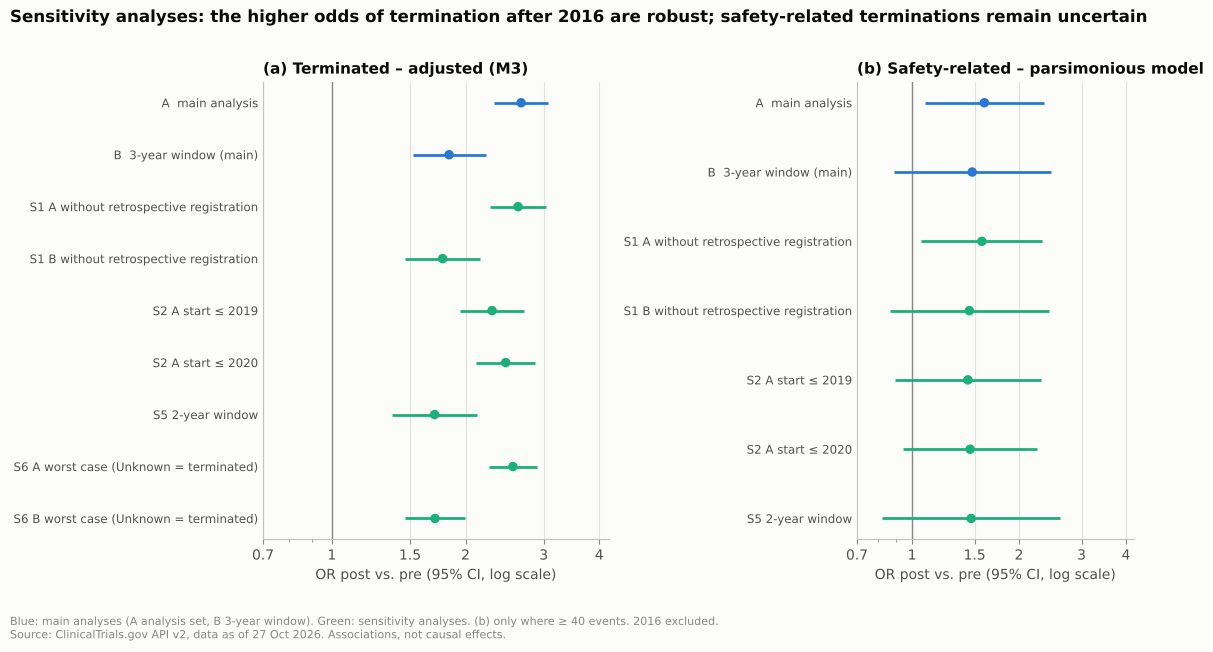

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 6), gridspec_kw={"width_ratios": [1.25, 1]})
for ax, key, title in [(axes[0], "_a_M3", "(a) Terminated – adjusted (M3)"),
                       (axes[1], "_b", "(b) Safety-related – parsimonious model")]:
    sub = sens_df[sens_df[key].notna()] if key in sens_df else sens_df.iloc[0:0]
    y = np.arange(len(sub))[::-1]
    est_ = np.array([v[0] for v in sub[key]]); lo_ = np.array([v[1] for v in sub[key]]); hi_ = np.array([v[2] for v in sub[key]])
    colors = [vs.SERIES[0] if s.startswith(("A ", "B ")) else vs.SERIES[2] for s in sub["scenario"]]
    ax.axvline(1, color=vs.INK_MUTED, lw=1)
    ax.hlines(y, lo_, hi_, colors=colors, lw=2)
    ax.scatter(est_, y, c=colors, s=34, zorder=3)
    ax.set_yticks(y, sub["scenario"], fontsize=8.5)
    ax.tick_params(axis="y", length=0)
    ax.set_xscale("log")
    ax.set_xlim(0.7, 4.2)
    ax.set_xticks([0.7, 1, 1.5, 2, 3, 4], ["0.7", "1", "1.5", "2", "3", "4"])
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)
    ax.set_xlabel("OR post vs. pre (95% CI, log scale)")
    ax.set_title(title, fontsize=11)
fig.suptitle("Sensitivity analyses: the higher odds of termination after 2016 are robust; "
             "safety-related terminations remain uncertain", x=0.01, ha="left", fontsize=12, fontweight="bold")
vs.source_note(fig, "Blue: main analyses (A analysis set, B 3-year window). Green: sensitivity analyses. (b) only where ≥ 40 events. "
               "2016 excluded.\nSource: ClinicalTrials.gov API v2, data as of 27 Oct 2026. Associations, not causal effects.", y=-0.03)
fig.tight_layout(rect=(0, 0, 1, 0.97))
vs.save(fig, FIGURES / "08_sensitivity_analyses.png")
plt.show()

## Summary of Part 2 (Block 14)

**(a) Termination – the period association is robust.** Adjusted ORs post vs. pre stay above 1
in every scenario: without retrospectively registered trials (A 2.63, B 1.78), start ≤ 2019 /
≤ 2020 (2.30 / 2.46), 2-year window (1.70) and the worst case with *Unknown* counted as terminated
(A 2.56, B 1.71). The window analyses (B, S5) consistently give smaller ORs (≈ 1.7–1.8) than the
analysis set (≈ 2.3–2.7) – part of the crude difference is right-censoring.

**Healthy volunteers vs. patients (S3, S4).** The termination share rose in **both** groups.
Healthy volunteers: within 3 years 4.1 % → 8.9 % (adjusted OR 2.14; excluding oncology 2.05).
Patients: 6.9 % → 10.1 % (adjusted OR 1.74; excluding oncology 1.71). The interaction
period × healthy volunteers is significant in the analysis set (interaction OR 0.62, p = 0.003),
but **not** in the fair 3-year window (1.36, 0.92–2.00, p = 0.13) and not without oncology – the
apparent difference is driven by right-censoring of long patient (oncology) trials. **There is no
robust evidence that the period effect differs between healthy-volunteer and patient trials**;
in particular, no relative decrease of terminations in healthy-volunteer trials after the revised
first-in-human guideline is visible.

**(b) Safety-related termination.** ORs 1.44–1.60 across scenarios; the CI includes 1 in all
analyses except the main analysis A and S1 A. Interaction with healthy volunteers exploratory
only (105 events): OR 1.46 (0.61–3.48). → **no robust change**.

**S7 EudraCT definition.** Share of prematurely ended trials among ended trials: **31.9 %**
(29.8–34.0) with the lenient rule (any country, D21) vs. **17.8 %** (16.1–19.6) with the strict
rule (all reporting countries, D22) – the EudraCT termination share depends strongly on the
definition (multi-country trials: 344 vs. 83 prematurely ended). Further interpretation in
Block 18.